# Semana 5 — Simulación HH y convergencia numérica

**Objetivo:** decidir qué paso temporal es suficiente para simular Hodgkin–Huxley,
comparando contra una simulación de referencia con un paso mucho más fino.

## Método

El paquete integra HH con Euler explícito:

$$\mathbf{x}_{k+1} = \mathbf{x}_k + \Delta t\, \mathbf{f}(\mathbf{x}_k, I_k), \qquad \mathbf{x} = (V, m, h, n)$$

Sin solución analítica, se usa como referencia $\Delta t_\text{ref} = 0.0025$ ms y se mide

$$\text{RMSE}(\Delta t) = \sqrt{\frac{1}{N}\sum_k \big(V_{\Delta t}(t_k) - V_\text{ref}(t_k)\big)^2}$$

Como Euler es de primer orden, el RMSE debe caer aproximadamente a la mitad cada vez que se
reduce $\Delta t$ a la mitad. El error se concentra en la subida del potencial de acción, donde
$dV/dt$ es mayor.

Estímulo: pulso de 10 µA/cm² entre 5 y 20 ms.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

from computational_neuroscience import current_pulse, simulate_hodgkin_huxley
from computational_neuroscience.outputs import save_data, save_figure

WEEK = 5
DURATION_MS = 30.0
REFERENCE_DT = 0.0025
STEPS = np.array([0.04, 0.02, 0.01])


def run(dt_ms: float):
    time = np.arange(0.0, DURATION_MS + dt_ms / 2, dt_ms)
    return simulate_hodgkin_huxley(current_pulse(time, 10.0, 5.0, 20.0), duration_ms=DURATION_MS, dt_ms=dt_ms)


reference = run(REFERENCE_DT)
results = {step: run(step) for step in STEPS}
differences = {
    step: np.interp(result.time_ms, reference.time_ms, reference.voltage_mv) - result.voltage_mv
    for step, result in results.items()
}
rmse = np.array([np.sqrt(np.mean(differences[step] ** 2)) for step in STEPS])
order = np.polyfit(np.log(STEPS), np.log(rmse), 1)[0]

## Figura

Arriba: voltaje con cada paso (las curvas casi se superponen). Centro: diferencia respecto a la
referencia, que se concentra en la subida del spike. Abajo: RMSE frente a $\Delta t$ (log–log).

Saved: weeks/week_05_hh_timestep/outputs/hh_timestep_convergence.png
Saved: weeks/week_05_hh_timestep/outputs/hh_timestep_errors.npz


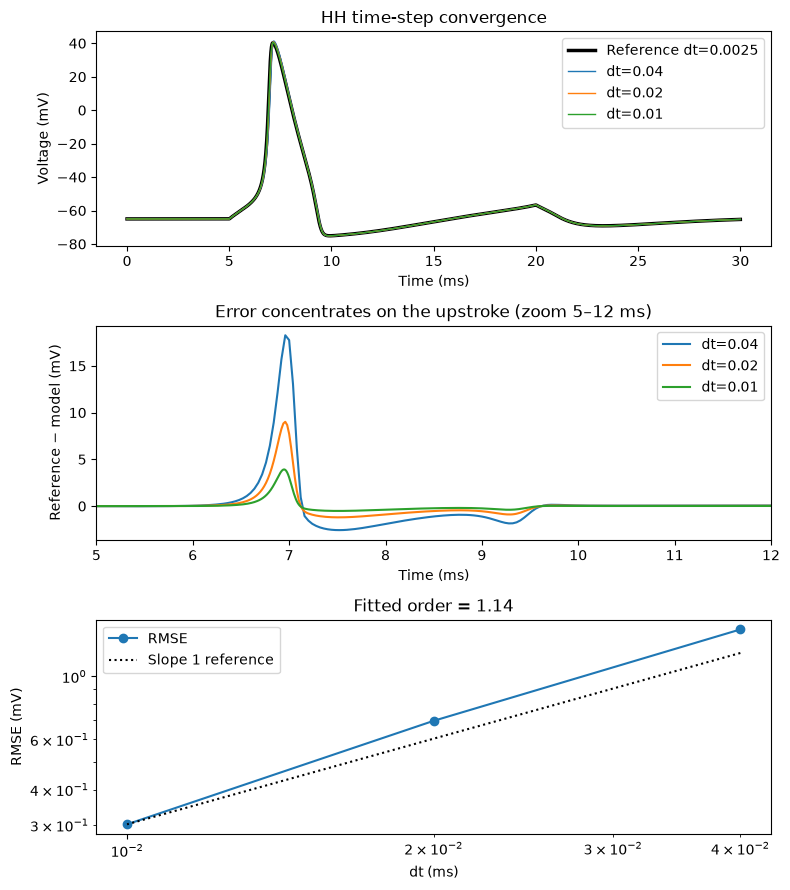

In [2]:
figure, axes = plt.subplots(3, 1, figsize=(8, 9))
axes[0].plot(reference.time_ms, reference.voltage_mv, color="black", linewidth=2.5, label=f"Reference dt={REFERENCE_DT:g}")
for step, result in results.items():
    axes[0].plot(result.time_ms, result.voltage_mv, linewidth=1, label=f"dt={step:g}")
    axes[1].plot(result.time_ms, differences[step], label=f"dt={step:g}")
axes[0].set(xlabel="Time (ms)", ylabel="Voltage (mV)", title="HH time-step convergence")
axes[0].legend()
axes[1].set(xlabel="Time (ms)", ylabel="Reference − model (mV)", xlim=(5, 12), title="Error concentrates on the upstroke (zoom 5–12 ms)")
axes[1].legend()
axes[2].loglog(STEPS, rmse, "o-", label="RMSE")
axes[2].loglog(STEPS, rmse[-1] * STEPS / STEPS[-1], "k:", label="Slope 1 reference")
axes[2].set(xlabel="dt (ms)", ylabel="RMSE (mV)", title=f"Fitted order = {order:.2f}")
axes[2].legend()
save_figure(WEEK, figure, "hh_timestep_convergence.png")
save_data(WEEK, "hh_timestep_errors.npz", dt_ms=STEPS, rmse_mv=rmse, reference_dt_ms=np.array(REFERENCE_DT))

## Validación

- El RMSE disminuye al reducir el paso.
- El orden ajustado está cerca de 1 (Euler).
- El número de potenciales de acción no depende del paso.
- Las compuertas permanecen en $[0, 1]$.

In [3]:
def spike_count(voltage: np.ndarray) -> int:
    return int(np.sum((voltage[1:] > 0.0) & (voltage[:-1] <= 0.0)))


assert np.all(np.diff(rmse) < 0)
assert 0.7 < order < 1.3, order
assert len({spike_count(result.voltage_mv) for result in results.values()} | {spike_count(reference.voltage_mv)}) == 1
for result in results.values():
    gates = np.concatenate((result.m, result.h, result.n))
    assert gates.min() >= 0.0 and gates.max() <= 1.0
print("Voltage RMSE (mV):", dict(zip(STEPS.tolist(), rmse.round(3).tolist())))
print(f"Fitted order: {order:.2f}; spikes per run: {spike_count(reference.voltage_mv)}")

Voltage RMSE (mV): {0.04: 1.461, 0.02: 0.698, 0.01: 0.302}
Fitted order: 1.14; spikes per run: 1


## Interpretación y límites

- Reducir $\Delta t$ a la mitad duplica el costo y reduce el error a la mitad: es el precio de
  un método de primer orden. Métodos de orden superior (RK4) o exponenciales son más eficientes.
- Pasos demasiado grandes no solo dan errores pequeños: pueden perder o inventar spikes.

**Para tu entrega:** prueba `dt_ms=0.1` y documenta qué cambia en el potencial de acción.